# FMCG Sales Analysis & Demand Forecasting

## Predictive Analytics Capstone Project

This project analyzes FMCG sales data from January 2022 to December 2024 to explore sales patterns, examine relationships between operational and promotional variables, and forecast aggregate daily units sold.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Statsmodels

**Key analyses:** Data cleaning, exploratory data analysis, correlation analysis, OLS regression, moving averages, and time-series forecasting.

### **Imports and Dataset Loading**

In [2]:
from google.colab import files
uploaded = files.upload()

Saving FMCG_2022_2024.csv to FMCG_2022_2024.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
import statsmodels.api as sm
import seaborn as sns
import os

df = pd.read_csv('FMCG_2022_2024.csv')
df.head()

,date,sku,brand,segment,category,channel,region,pack_type,price_unit,promotion_flag,delivery_days,stock_available,delivered_qty,units_sold
0,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-Central,Multipack,2.38,0,1,141,128,9
1,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-North,Single,1.55,1,3,0,129,0
2,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Retail,PL-South,Carton,4.00,0,5,118,161,8
3,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Discount,PL-Central,Single,5.16,0,2,81,114,7
4,2022-01-21,MI-006,MiBrand1,Milk-Seg3,Milk,Discount,PL-North,Single,7.66,0,4,148,204,12


### **Data Cleaning**

In [4]:
df_clean = df.dropna(
    subset=['units_sold', 'date', 'sku', 'brand', 'region']
).copy()

df_clean['date'] = pd.to_datetime(
    df_clean['date'], errors='coerce'
)

df_clean = df_clean.dropna(subset=['date']).copy()
df_clean = df_clean[df_clean['units_sold'] >= 0].copy()
df_clean = df_clean.reset_index(drop=True)

numeric_df = df_clean.select_dtypes(include=['number'])

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))

df_clean.shape, df_clean.head()

Original records: 190757
Cleaned records: 190754
Records removed: 3


((190754, 14),
         date     sku     brand    segment category   channel      region  \
 0 2022-01-21  MI-006  MiBrand1  Milk-Seg3     Milk    Retail  PL-Central   
 1 2022-01-21  MI-006  MiBrand1  Milk-Seg3     Milk    Retail    PL-North   
 2 2022-01-21  MI-006  MiBrand1  Milk-Seg3     Milk    Retail    PL-South   
 3 2022-01-21  MI-006  MiBrand1  Milk-Seg3     Milk  Discount  PL-Central   
 4 2022-01-21  MI-006  MiBrand1  Milk-Seg3     Milk  Discount    PL-North   
 
    pack_type  price_unit  promotion_flag  delivery_days  stock_available  \
 0  Multipack        2.38               0              1              141   
 1     Single        1.55               1              3                0   
 2     Carton        4.00               0              5              118   
 3     Single        5.16               0              2               81   
 4     Single        7.66               0              4              148   
 
    delivered_qty  units_sold  
 0            128        

### **Data Description & Data Classification**

In [5]:
# Data Description & Data Classification
print("Descriptive Statistics:")
print(df_clean.describe())

print("Data Classification:")
print(df_clean.dtypes)

Descriptive Statistics:
                                date     price_unit  promotion_flag  \
count                         190754  190754.000000   190754.000000   
mean   2023-10-28 04:11:30.581587200       5.251989        0.149197   
min              2022-01-21 00:00:00       1.500000        0.000000   
25%              2023-04-16 00:00:00       3.380000        0.000000   
50%              2023-11-12 00:00:00       5.250000        0.000000   
75%              2024-06-07 00:00:00       7.130000        0.000000   
max              2024-12-31 00:00:00       9.000000        1.000000   
std                              NaN       2.166692        0.356284   

       delivery_days  stock_available  delivered_qty     units_sold  
count  190754.000000    190754.000000  190754.000000  190754.000000  
mean        3.004839       157.700237     179.336585      19.920211  
min         1.000000         0.000000       1.000000       0.000000  
25%         2.000000       124.000000     152.000000    

### **Exploratory Data Analysis and Correlation Matrix**

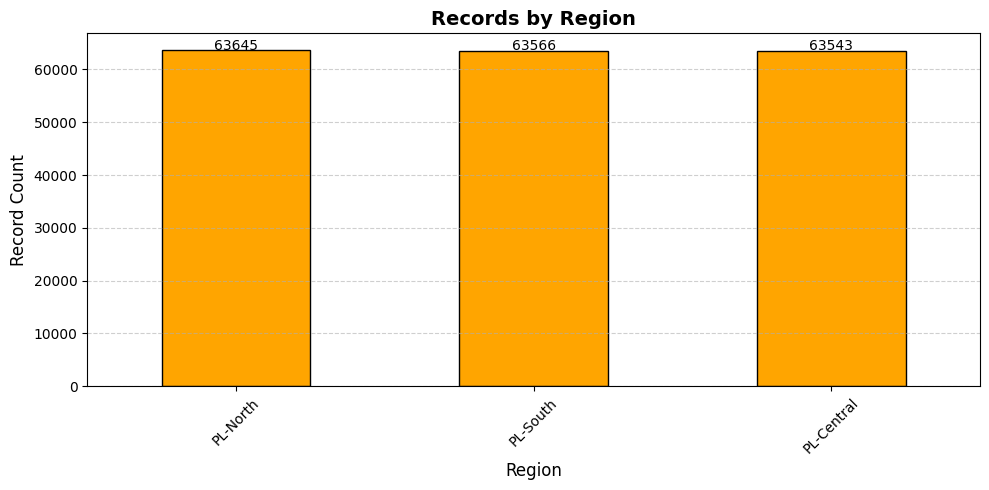

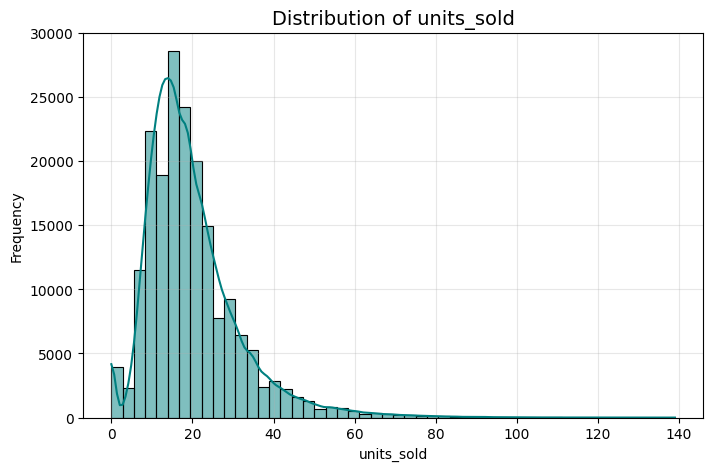

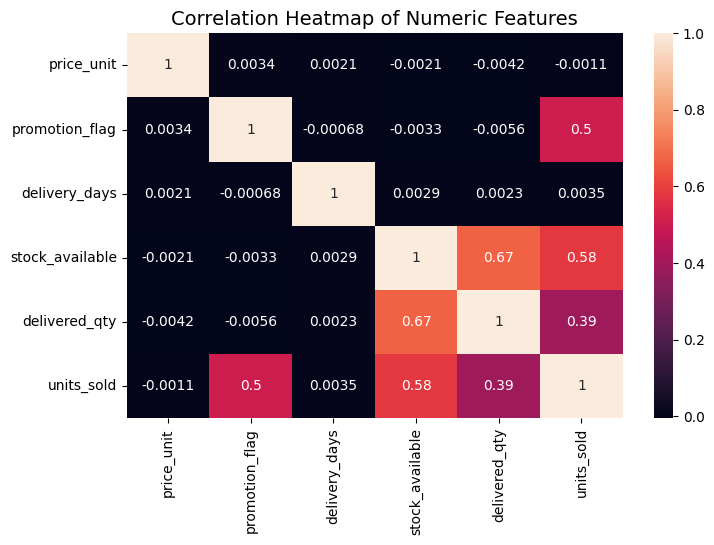

In [6]:
top_regions = df_clean['region'].value_counts().head(10)

plt.figure(figsize=(10,5))
top_regions.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Records by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Record Count', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
for i,v in enumerate(top_regions):
    plt.text(i, v+50, str(v), ha='center')
plt.tight_layout()
plt.show()

# Distribution of units_sold
plt.figure(figsize=(8,5))
sns.histplot(df_clean['units_sold'], bins=50, color='teal', kde=True)
plt.title('Distribution of units_sold', fontsize=14)
plt.xlabel('units_sold')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8,5))
sns.heatmap(df_clean.select_dtypes('number').corr(), annot=True)
plt.title('Correlation Heatmap of Numeric Features', fontsize=14)
plt.show()


### **Regressional Analysis for Feature Selection**

In [7]:
# OLS Regression
import statsmodels.api as sm

x = df_clean[['price_unit','promotion_flag','delivery_days','stock_available','delivered_qty']]
y = df_clean['units_sold']
x = sm.add_constant(x)

model = sm.OLS(y, x).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             units_sold   R-squared:                       0.592
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                 5.533e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:03:49   Log-Likelihood:            -6.5550e+05
No. Observations:              190754   AIC:                         1.311e+06
Df Residuals:                  190748   BIC:                         1.311e+06
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -3.2009      0.097    -

### **Time Series Analysis**

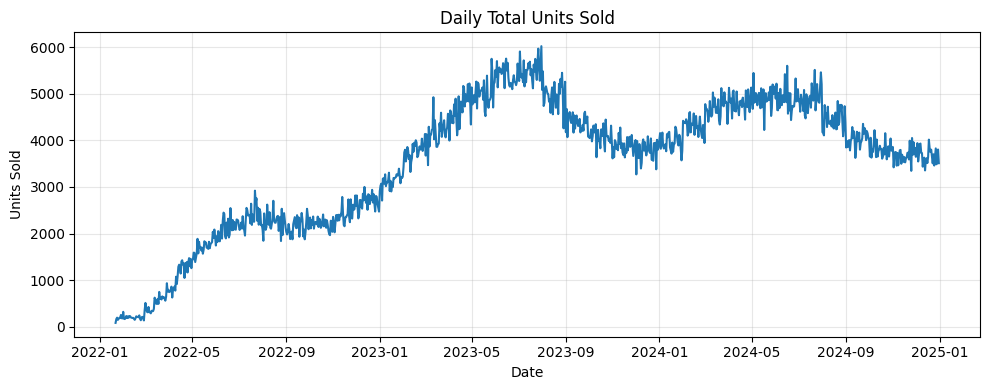

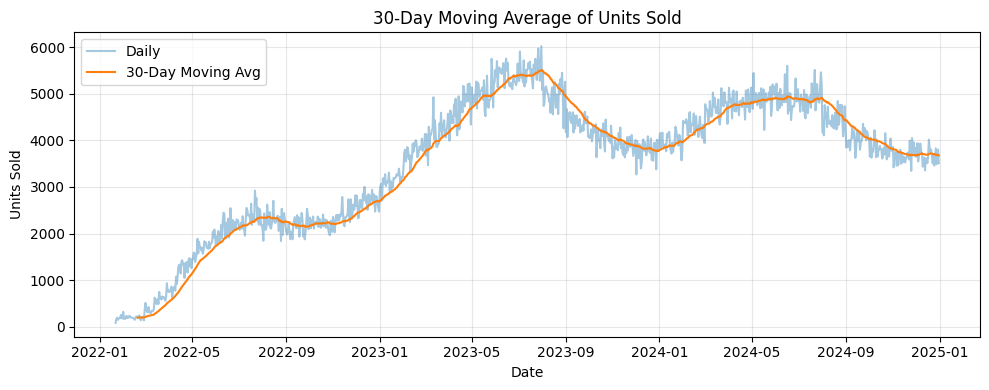

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


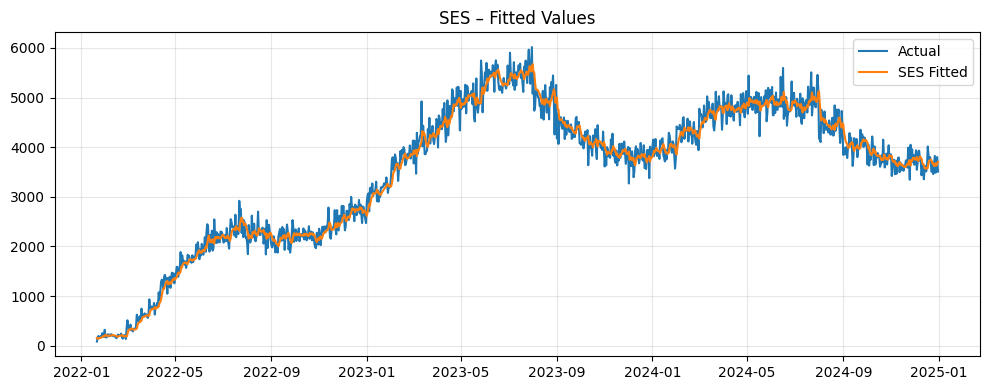

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


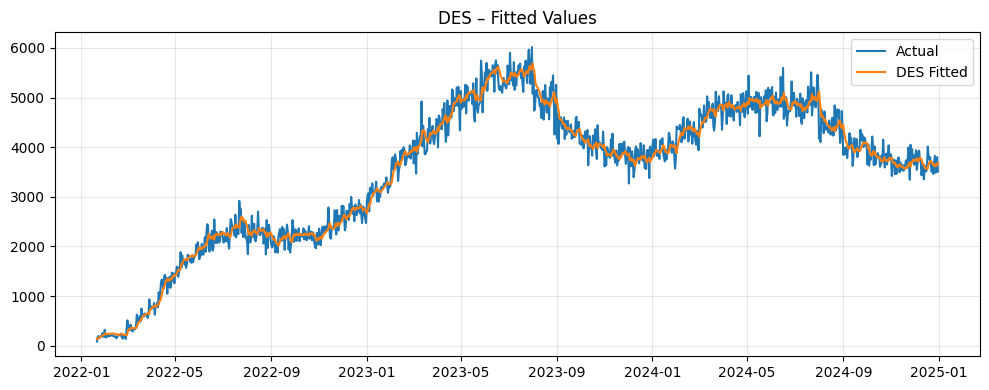

In [10]:
# Time Series – Total units_sold
ts = df_clean.groupby('date')['units_sold'].sum()

plt.figure(figsize=(10,4))
plt.plot(ts.index, ts.values)
plt.title('Daily Total Units Sold')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 30-Day Moving Average
ma30 = ts.rolling(30).mean()

plt.figure(figsize=(10,4))
plt.plot(ts.index, ts.values, alpha=0.4, label='Daily')
plt.plot(ma30.index, ma30.values, label='30-Day Moving Avg')
plt.title('30-Day Moving Average of Units Sold')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# SES
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Explicitly passing initialization_method='estimated' to fix the TypeError
ses_model = SimpleExpSmoothing(ts, initialization_method='estimated').fit()
ses_fitted = ses_model.fittedvalues
ses_forecast = ses_model.forecast(90)

plt.figure(figsize=(10,4))
plt.plot(ts.index, ts.values, label='Actual')
plt.plot(ses_fitted.index, ses_fitted.values, label='SES Fitted')
plt.title('SES – Fitted Values')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# DES
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Explicitly passing initialization_method='estimated' to fix the TypeError
des_model = ExponentialSmoothing(ts, trend='add', initialization_method='estimated').fit()
des_fitted = des_model.fittedvalues
des_forecast = des_model.forecast(90)

plt.figure(figsize=(10,4))
plt.plot(ts.index, ts.values, label='Actual')
plt.plot(des_fitted.index, des_fitted.values, label='DES Fitted')
plt.title('DES – Fitted Values')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Forecast accuracy comparison:


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,MAE,RMSE
Model,,
Last-Value Baseline,144.97,188.58
DES,217.81,274.83
SES,265.23,302.49


Model with the lowest test-period MAE: Last-Value Baseline


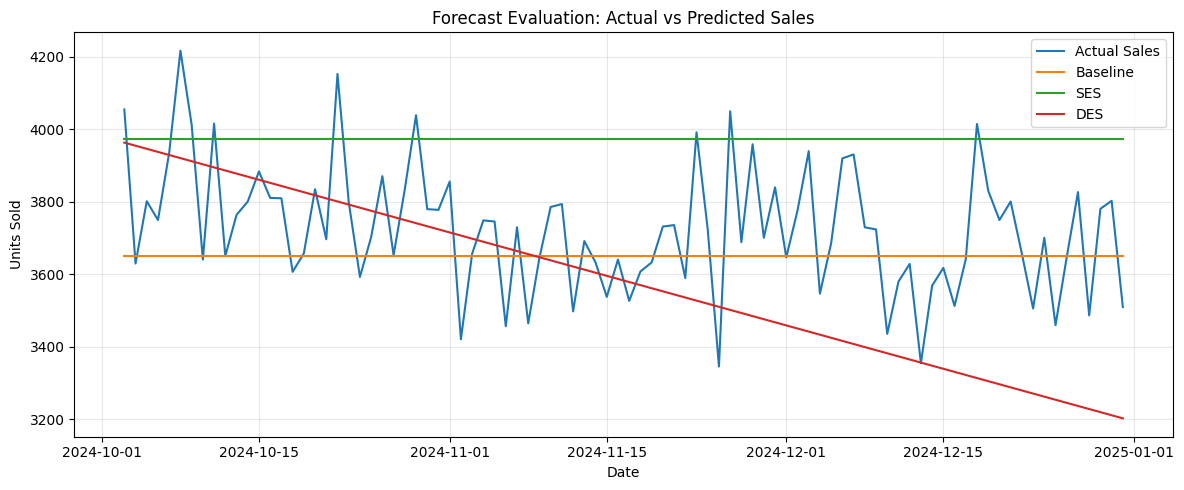


Final 90-day forecast:


,date,forecast_units_sold
0,2025-01-01,3509
1,2025-01-02,3509
2,2025-01-03,3509
3,2025-01-04,3509
4,2025-01-05,3509
5,2025-01-06,3509
6,2025-01-07,3509
7,2025-01-08,3509
8,2025-01-09,3509
9,2025-01-10,3509


Saved: FMCG_90_Day_Forecast.csv


In [11]:
# Forecast Evaluation: SES vs DES
# Compare models on the last 90 observations not used for fitting

# Ensure the aggregated time-series 'ts' is defined
if 'ts' not in globals():
    if 'df_clean' in globals():
        ts = df_clean.groupby('date')['units_sold'].sum()
    else:
        raise NameError("Neither 'ts' nor 'df_clean' is defined. Please run the data cleaning cells first.")

test_size = 90

if len(ts) <= test_size:
    raise ValueError("Not enough observations for a 90-observation test set.")

train = ts.iloc[:-test_size]
test = ts.iloc[-test_size:]

# Baseline: predict the last training value for every test observation
baseline_pred = np.repeat(train.iloc[-1], len(test))

# Simple Exponential Smoothing (using explicit estimated initialization)
ses_test_model = SimpleExpSmoothing(train, initialization_method='estimated').fit()
ses_pred = np.asarray(ses_test_model.forecast(len(test)))

# Double Exponential Smoothing (using explicit estimated initialization)
des_test_model = ExponentialSmoothing(
    train, trend='add', initialization_method='estimated'
).fit()
des_pred = np.asarray(des_test_model.forecast(len(test)))

actual = test.to_numpy()

# Calculate forecast errors
forecast_metrics = pd.DataFrame([
    {
        'Model': 'Last-Value Baseline',
        'MAE': np.mean(np.abs(actual - baseline_pred)),
        'RMSE': np.sqrt(np.mean((actual - baseline_pred) ** 2))
    },
    {
        'Model': 'SES',
        'MAE': np.mean(np.abs(actual - ses_pred)),
        'RMSE': np.sqrt(np.mean((actual - ses_pred) ** 2))
    },
    {
        'Model': 'DES',
        'MAE': np.mean(np.abs(actual - des_pred)),
        'RMSE': np.sqrt(np.mean((actual - des_pred) ** 2))
    }
]).set_index('Model').sort_values('MAE')

print("Forecast accuracy comparison:")
display(forecast_metrics.round(2))

best_model_name = forecast_metrics['MAE'].idxmin()
print("Model with the lowest test-period MAE:", best_model_name)

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(test.index, actual, label='Actual Sales')
plt.plot(test.index, baseline_pred, label='Baseline')
plt.plot(test.index, ses_pred, label='SES')
plt.plot(test.index, des_pred, label='DES')

plt.title('Forecast Evaluation: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Refit the selected model on the full series for the final 90-day forecast
if best_model_name == 'SES':
    final_model = SimpleExpSmoothing(ts, initialization_method='estimated').fit()
    future_values = np.asarray(final_model.forecast(90))

elif best_model_name == 'DES':
    final_model = ExponentialSmoothing(
        ts, trend='add', initialization_method='estimated'
    ).fit()
    future_values = np.asarray(final_model.forecast(90))

else:
    future_values = np.repeat(ts.iloc[-1], 90)

future_dates = pd.date_range(
    start=ts.index[-1] + pd.Timedelta(days=1),
    periods=90,
    freq='D'
)

forecast_output = pd.DataFrame({
    'date': future_dates,
    'forecast_units_sold': future_values
})

print("\nFinal 90-day forecast:")
display(forecast_output.head(10))

forecast_output.to_csv('FMCG_90_Day_Forecast.csv', index=False)
print("Saved: FMCG_90_Day_Forecast.csv")